## Análisis de Datos Meteorológicos con una API Pública
Obtener datos del clima de una ciudad usando la API de Open-Meteo (https://open-meteo.com/) y mostrar el pronóstico para Bilbao.

* Haz una petición a la API para que devuelva el pronóstico de las temperaturas para una semana en Bilbao. Tip: el parámetro correspondiente en el query es `temperature_2m` además de la latitud y la longitud.
* Procesa la respuesta en formato JSON para obtener dos listas: una con la lista de temperaturas y otra con las fechas-horas correspondientes.
* Crea un DataFrame con esas dos columnas: `Hora` y `Temperatura`
* Elige la gráfica adecuada y visualiza el pronóstico de temperaturas.

Para crear la variable `Hora` del DataFrame puedes introducir directamente la lista que se obtiene del campo `data["hourly"]["time"]` o procesar esa lista mediante el siguiente código:

`hours = pd.date_range(start=lista_de_horas, periods=len(temps), freq="H")`

In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

# Coordenadas de Bilbao
latitude = 43.2540
longitude = -2.9230

url = "https://api.open-meteo.com/v1/forecast"

params = {
    "latitude": latitude,
    "longitude": longitude,
    "hourly": "temperature_2m",
    "forecast_days": 7,
    "timezone": "Europe/Madrid"
}

response = requests.get(url, params=params)
response.raise_for_status()  # muestra un error si falla la petición

data = response.json()

temps = data["hourly"]["temperature_2m"]
horas = data["hourly"]["time"]

df = pd.DataFrame({
    "Hora": pd.to_datetime(horas),
    "Temperatura": temps
})

df.head()

,Hora,Temperatura
0,2026-11-08 00:00:00,14.8
1,2026-11-08 01:00:00,15.3
2,2026-11-08 02:00:00,15.6
3,2026-11-08 03:00:00,15.6
4,2026-11-08 04:00:00,15.8


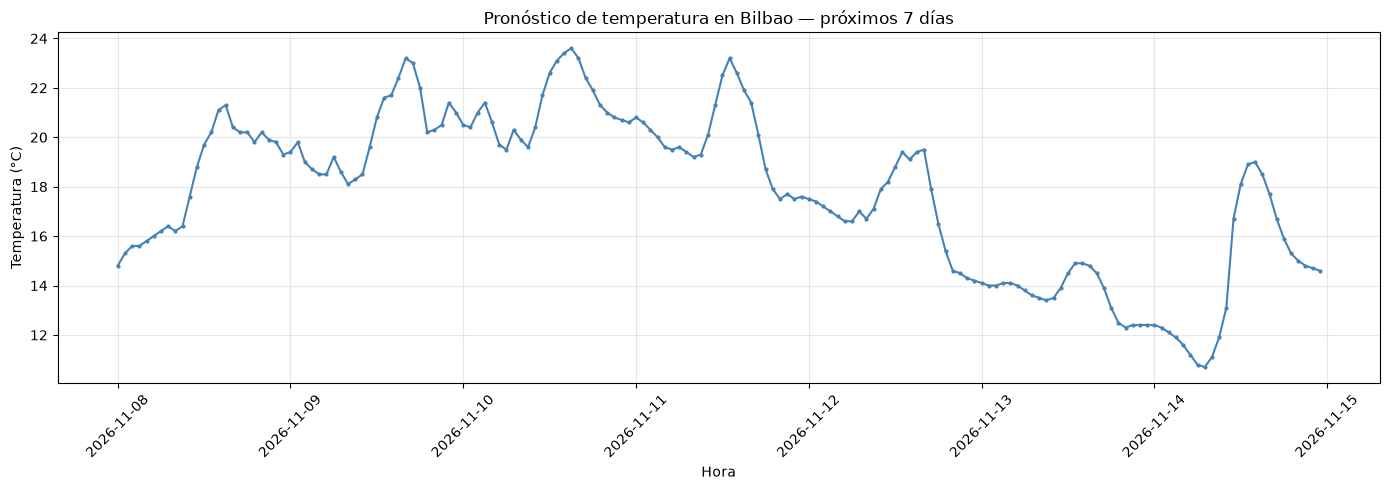

In [3]:
plt.figure(figsize=(14, 5))

plt.plot(
    df["Hora"],
    df["Temperatura"],
    color="steelblue",
    marker="o",
    markersize=2
)

plt.title("Pronóstico de temperatura en Bilbao — próximos 7 días")
plt.xlabel("Hora")
plt.ylabel("Temperatura (°C)")
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()